# Image Mining – Part 2: shot-cut detection

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import median_filter, maximum_filter1d, gaussian_filter

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

VIDEO_DIR = "."
VIDEOS = {
    "Matrix": f"{VIDEO_DIR}/Extrait5-Matrix-Helicopter_Scene(280p).m4v",
    "Cosmos": f"{VIDEO_DIR}/Extrait1-Cosmos_Laundromat1(340p).m4v",
}
REFERENCE = {
    "Matrix": [62, 103, 146, 208, 253, 296, 361, 409, 447, 512, 621, 679, 712, 745],
    "Cosmos": [250, 479, 511, 600, 653, 691, 1114, 1181, 1310, 1415, 1517, 1565,
               1712, 1781, 1864, 1989, 2047, 2166, 2216, 2278, 2442, 2512, 2559,
               2637, 2714, 2765, 2838, 3020, 3094, 3131, 3162],
}

## Setup (same for every trial)

In [2]:
THUMB_W, THUMB_H = 192, 96

def read_frames(path):
    try:
        import av
        with av.open(path) as container:
            for frame in container.decode(video=0):
                yield frame.to_ndarray(format="rgb24")
    except ImportError:
        import cv2
        cap = cv2.VideoCapture(path)
        while True:
            ok, bgr = cap.read()
            if not ok:
                break
            yield cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def load_thumbs(path):
    thumbs, ar = [], None
    for rgb in read_frames(path):
        ar = ar or rgb.shape[1] / rgb.shape[0]
        thumbs.append(np.asarray(Image.fromarray(rgb).resize((THUMB_W, THUMB_H), Image.BOX)))
    if not thumbs:
        raise FileNotFoundError(f"no frame decoded from {path} - check VIDEO_DIR and the file name")
    return np.stack(thumbs), ar

VIDEO = {}
for name, path in VIDEOS.items():
    thumbs, ar = load_thumbs(path)
    VIDEO[name] = dict(thumbs=thumbs, ar=ar)
    print(f"{name}: {len(thumbs)} frames, {len(REFERENCE[name])} reference cuts")

Matrix: 768 frames, 14 reference cuts
Cosmos: 3168 frames, 31 reference cuts


In [3]:
PARAMS = dict(window=15, ratio=4.0, floor=0.10, nms=5)

def detect(score, window, ratio, floor, nms):
    local = median_filter(score, size=2 * window + 1, mode="nearest")
    keep = (score > floor) & (score > ratio * (local + 1e-3)) & (score == maximum_filter1d(score, nms))
    return np.flatnonzero(keep).tolist()

def match(pred, ref, tol=1):
    used, pairs = set(), []
    for r in ref:
        for p in sorted(pred, key=lambda p: abs(p - r)):
            if p not in used and abs(p - r) <= tol:
                used.add(p); pairs.append((p, r)); break
    matched_ref = {r for _, r in pairs}
    fp = [p for p in pred if p not in used]; fn = [r for r in ref if r not in matched_ref]
    tp = len(pairs); prec = tp / max(len(pred), 1); rec = tp / max(len(ref), 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    return dict(TP=tp, FP=len(fp), FN=len(fn), precision=prec, recall=rec, F1=f1,
                matched=pairs, false_pos=fp, missed=fn)

## Descriptors and score

In [4]:
def block_mean(x, k):
    n, h, w, c = x.shape
    return x.reshape(n, h // k, k, w // k, k, c).mean((2, 4))

def color_hist(thumbs, bins=8):
    small = (block_mean(thumbs, 3).astype(np.uint8) // (256 // bins)).astype(int)
    idx = (small[..., 0] * bins + small[..., 1]) * bins + small[..., 2]
    H = np.stack([np.bincount(i.ravel(), minlength=bins ** 3) for i in idx]).astype(float)
    return H / H.sum(1, keepdims=True)

def gray_layout(thumbs):
    g = block_mean(thumbs, 6).mean(-1).reshape(len(thumbs), -1)
    g = g - g.mean(1, keepdims=True)
    return g / (np.linalg.norm(g, axis=1, keepdims=True) + 1e-3 * np.sqrt(g.shape[1]))

def hog_layout(thumbs, cell=16, nbins=8, cellnorm=False):
    g = gaussian_filter(thumbs.astype(np.float32).mean(-1), (0, 1, 1))
    gy, gx = np.gradient(g, axis=(1, 2))
    mag = np.hypot(gx, gy)
    ang = (np.arctan2(gy, gx) % np.pi) / np.pi * nbins
    b0 = np.floor(ang).astype(int) % nbins; w1 = ang - np.floor(ang); b1 = (b0 + 1) % nbins
    n, h, w = g.shape; ch, cw = h // cell, w // cell
    out = np.zeros((n, ch, cw, nbins), np.float32)
    for b in range(nbins):
        m = mag * ((b0 == b) * (1 - w1) + (b1 == b) * w1)
        out[..., b] = m[:, :ch * cell, :cw * cell].reshape(n, ch, cell, cw, cell).sum((2, 4))
    if cellnorm:
        e = np.linalg.norm(out, axis=-1, keepdims=True)
        out = out / (e + 0.1 * e.mean((1, 2, 3), keepdims=True) + 1e-6)
    out = out.reshape(n, -1)
    return out / (np.linalg.norm(out, axis=1, keepdims=True) + 1e-6)

_cache = {}
def descriptors(name, layout, cell=16, cellnorm=False):
    key = (name, layout, cell, cellnorm)
    if key not in _cache:
        T = VIDEO[name]["thumbs"]
        L = gray_layout(T) if layout == "gray" else hog_layout(T, cell, cellnorm=cellnorm)
        _cache[key] = (color_hist(T) if (name, "H") not in _cache else _cache[(name, "H")], L)
        _cache[(name, "H")] = _cache[key][0]
    return _cache[key]

def pair_distance(H, L, i, j):
    n = len(H); i, j = np.clip(i, 0, n - 1), np.clip(j, 0, n - 1)
    d_color = 1 - np.minimum(H[i], H[j]).sum(1)
    d_layout = (1 - (L[i] * L[j]).sum(1)).clip(0)
    return np.minimum(d_color, d_layout), d_color, d_layout

def frame_scores(name, layout="hog", before=2, after=2, cell=16, cellnorm=False):
    H, L = descriptors(name, layout, cell, cellnorm)
    t = np.arange(len(H))
    S = np.array([pair_distance(H, L, t - di, t + dj)[0] for di in range(1, before + 1) for dj in range(after)])
    score = S.min(0); score[0] = 0
    return score

def evaluate(score, name):
    return match(detect(score, **PARAMS), REFERENCE[name])

def trial_table(variants):
    print(f"{'variant':<44}| {'Matrix TP/FP/FN':>16} {'F1':>6} | {'Cosmos TP/FP/FN':>16} {'F1':>6}")
    for label, kw in variants.items():
        rm, rc = (evaluate(frame_scores(n, **kw), n) for n in ["Matrix", "Cosmos"])
        print(f"{label:<44}| {rm['TP']:>5}/{rm['FP']}/{rm['FN']:<8} {rm['F1']:>6.3f} | {rc['TP']:>5}/{rc['FP']}/{rc['FN']:<8} {rc['F1']:>6.3f}")

## Trial 0: first approach (v1)

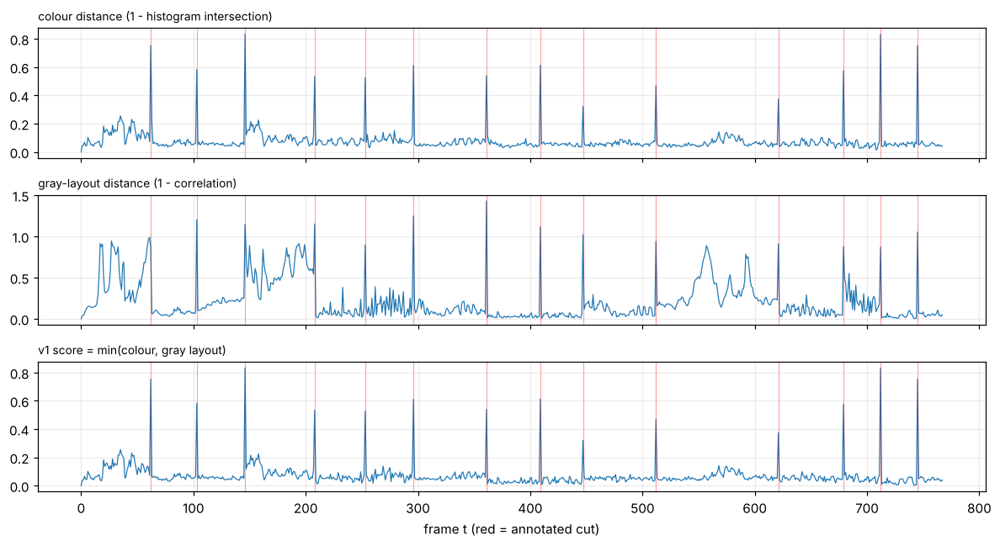

In [5]:
for name in VIDEO:
    VIDEO[name]["score_v1"] = frame_scores(name, layout="gray", before=1, after=1)

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
H, L = descriptors("Matrix", "gray"); t = np.arange(len(H))
_, dc, dl = pair_distance(H, L, t - 1, t); dc[0] = dl[0] = 0
for ax, y, title in zip(axes, [dc, dl, VIDEO["Matrix"]["score_v1"]],
        ["colour distance (1 - histogram intersection)", "gray-layout distance (1 - correlation)", "v1 score = min(colour, gray layout)"]):
    ax.plot(y, lw=.8); ax.set_title(title, fontsize=9, loc="left")
    for r in REFERENCE["Matrix"]: ax.axvline(r, c="r", alpha=.35, lw=.8)
axes[-1].set_xlabel("frame t (red = annotated cut)"); plt.tight_layout(); plt.show()

== v1 - Matrix ==  TP=14  FP=0  FN=0  P=1.000  R=1.000  F1=1.000
matched (pred, ref): [(62, 62), (103, 103), (146, 146), (208, 208), (253, 253), (296, 296), (361, 361), (409, 409), (447, 447), (512, 512), (621, 621), (679, 679), (712, 712), (745, 745)]
false positives (frame, score): []
missed references (frame, score): []
== v1 - Cosmos ==  TP=30  FP=10  FN=1  P=0.750  R=0.968  F1=0.845
matched (pred, ref): [(250, 250), (479, 479), (511, 511), (600, 600), (653, 653), (691, 691), (1114, 1114), (1181, 1181), (1310, 1310), (1415, 1415), (1517, 1517), (1565, 1565), (1712, 1712), (1781, 1781), (1864, 1864), (1989, 1989), (2047, 2047), (2166, 2166), (2216, 2216), (2278, 2278), (2442, 2442), (2512, 2512), (2559, 2559), (2637, 2637), (2714, 2714), (2765, 2765), (2838, 2838), (3094, 3094), (3131, 3131), (3162, 3162)]
false positives (frame, score): [(471, 0.1), (1168, 0.11), (1217, 0.18), (1525, 0.29), (1547, 0.82), (1715, 0.23), (1732, 0.27), (1765, 0.49), (1768, 0.2), (2757, 0.46)]
missed re

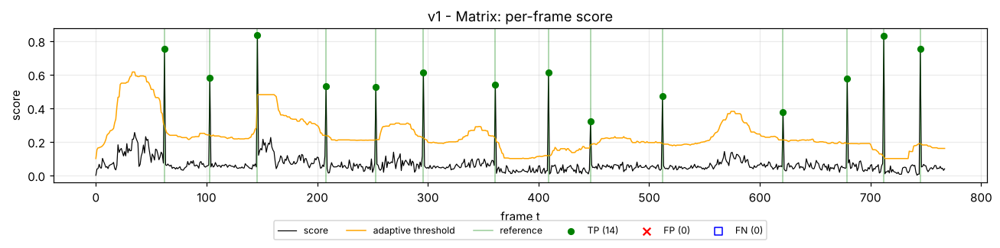

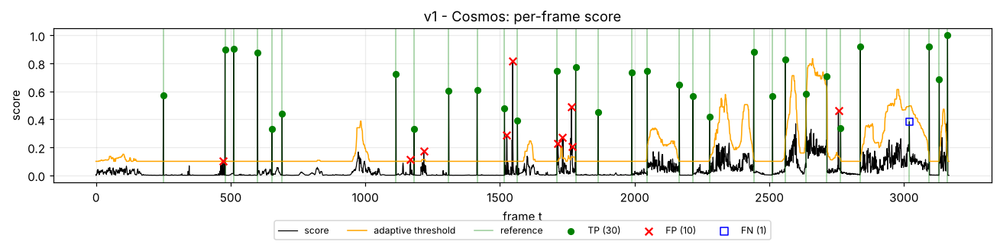

In [6]:
def show(name, key, title):
    s = VIDEO[name][key]; pred = detect(s, **PARAMS); r = match(pred, REFERENCE[name])
    VIDEO[name].setdefault("pred", {})[key] = pred; VIDEO[name].setdefault("res", {})[key] = r
    print(f"== {title} - {name} ==  TP={r['TP']}  FP={r['FP']}  FN={r['FN']}  P={r['precision']:.3f}  R={r['recall']:.3f}  F1={r['F1']:.3f}")
    print("matched (pred, ref):", r["matched"])
    print("false positives (frame, score):", [(p, round(float(s[p]), 2)) for p in r["false_pos"]])
    print("missed references (frame, score):", [(q, round(float(s[q]), 2)) for q in r["missed"]])
    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.plot(s, lw=.8, c="k", label="score")
    local = median_filter(s, size=2 * PARAMS["window"] + 1, mode="nearest")
    ax.plot(np.maximum(PARAMS["ratio"] * (local + 1e-3), PARAMS["floor"]), c="orange", lw=1, label="adaptive threshold")
    for i, q in enumerate(REFERENCE[name]): ax.axvline(q, c="g", alpha=.4, lw=1, label="reference" if i == 0 else None)
    tp = [p for p, _ in r["matched"]]
    ax.scatter(tp, s[tp], c="g", s=25, zorder=3, label=f"TP ({r['TP']})")
    ax.scatter(r["false_pos"], s[r["false_pos"]], c="r", marker="x", s=40, zorder=3, label=f"FP ({r['FP']})")
    ax.scatter(r["missed"], s[r["missed"]], edgecolors="b", marker="s", s=40, facecolors="none", zorder=3, label=f"FN ({r['FN']})")
    ax.set(title=f"{title} - {name}: per-frame score", xlabel="frame t", ylabel="score")
    ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22)); plt.tight_layout(); plt.show()

show("Matrix", "score_v1", "v1")
show("Cosmos", "score_v1", "v1")

## Trial 1: what goes wrong on Cosmos?

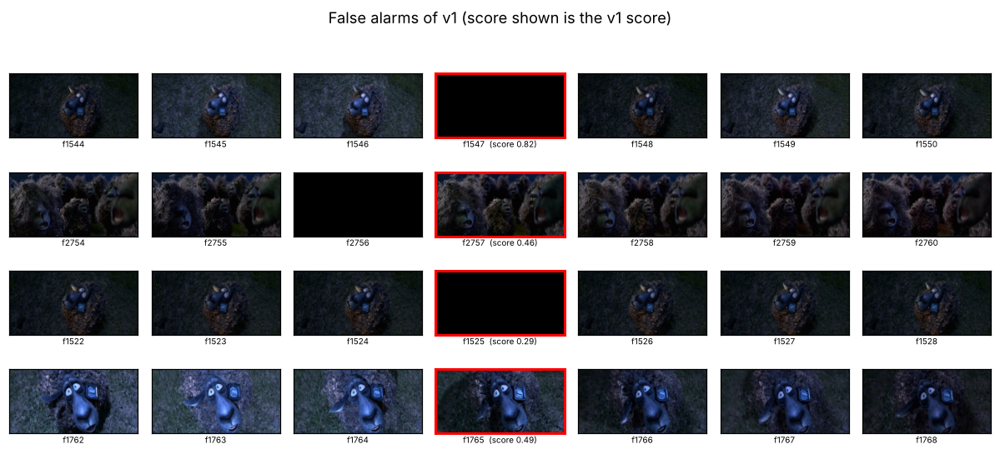

In [7]:
def gallery(name, frames, key, title, span=3):
    T = VIDEO[name]["thumbs"]; s = VIDEO[name][key]
    fig, ax = plt.subplots(len(frames), 2 * span + 1, figsize=(11, 1.25 * len(frames)), squeeze=False)
    for row, t in zip(ax, frames):
        for j, o in enumerate(range(-span, span + 1)):
            f = min(max(t + o, 0), len(T) - 1); row[j].imshow(T[f]); row[j].set_xticks([]); row[j].set_yticks([]); row[j].grid(False)
            row[j].set_xlabel(f"f{f}" + (f"  (score {s[t]:.2f})" if o == 0 else ""), fontsize=6.5, labelpad=1)
            if o == 0:
                for sp in row[j].spines.values(): sp.set_edgecolor("red"); sp.set_linewidth(2)
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

gallery("Cosmos", [1547, 2757, 1525, 1765], "score_v1", "False alarms of v1 (score shown is the v1 score)")

## Trial 2: a layout descriptor that ignores lighting (HOG)

In [8]:
trial_table({
    "v1: gray layout (reference)":               dict(layout="gray", before=1, after=1),
    "2a: HOG, cells 8x8 px":                     dict(layout="hog", cell=8,  before=1, after=1),
    "2b: HOG, cells 12x12 px":                   dict(layout="hog", cell=12, before=1, after=1),
    "2c: HOG 16x16 px, per-cell normalisation":  dict(layout="hog", cell=16, cellnorm=True, before=1, after=1),
    "2d: HOG, cells 16x16 px":                   dict(layout="hog", cell=16, before=1, after=1),
})

variant                                     |  Matrix TP/FP/FN     F1 |  Cosmos TP/FP/FN     F1
v1: gray layout (reference)                 |    14/0/0         1.000 |    30/10/1         0.845
2a: HOG, cells 8x8 px                       |    14/0/0         1.000 |    29/6/2         0.879
2b: HOG, cells 12x12 px                     |    14/0/0         1.000 |    28/6/3         0.862
2c: HOG 16x16 px, per-cell normalisation    |    13/0/1         0.963 |    24/4/7         0.814
2d: HOG, cells 16x16 px                     |    14/0/0         1.000 |    29/5/2         0.892


## Trial 3: compare several frames instead of two

In [9]:
trial_table({
    "3a: gray, 1+1 (= v1)":    dict(layout="gray", before=1, after=1),
    "3b: gray, 2+2":           dict(layout="gray", before=2, after=2),
    "3c: gray, 3+3":           dict(layout="gray", before=3, after=3),
    "3d: HOG, 1+1":            dict(layout="hog",  before=1, after=1),
    "3e: HOG, 2+2":            dict(layout="hog",  before=2, after=2),
    "3f: HOG, 3+3":            dict(layout="hog",  before=3, after=3),
})

variant                                     |  Matrix TP/FP/FN     F1 |  Cosmos TP/FP/FN     F1
3a: gray, 1+1 (= v1)                        |    14/0/0         1.000 |    30/10/1         0.845
3b: gray, 2+2                               |    14/0/0         1.000 |    30/8/1         0.870
3c: gray, 3+3                               |    14/0/0         1.000 |    30/7/1         0.882
3d: HOG, 1+1                                |    14/0/0         1.000 |    29/5/2         0.892
3e: HOG, 2+2                                |    14/0/0         1.000 |    29/3/2         0.921
3f: HOG, 3+3                                |    14/0/0         1.000 |    28/2/3         0.918


## Trial 4: final version (v2) = HOG layout + 2+2 window

== v2 - Matrix ==  TP=14  FP=0  FN=0  P=1.000  R=1.000  F1=1.000
matched (pred, ref): [(62, 62), (103, 103), (146, 146), (208, 208), (253, 253), (296, 296), (361, 361), (409, 409), (447, 447), (512, 512), (621, 621), (679, 679), (712, 712), (745, 745)]
false positives (frame, score): []
missed references (frame, score): []
== v2 - Cosmos ==  TP=29  FP=3  FN=2  P=0.906  R=0.935  F1=0.921
matched (pred, ref): [(250, 250), (479, 479), (511, 511), (600, 600), (653, 653), (691, 691), (1114, 1114), (1181, 1181), (1310, 1310), (1415, 1415), (1517, 1517), (1565, 1565), (1712, 1712), (1781, 1781), (1864, 1864), (1989, 1989), (2047, 2047), (2166, 2166), (2216, 2216), (2278, 2278), (2442, 2442), (2512, 2512), (2559, 2559), (2637, 2637), (2765, 2765), (2838, 2838), (3094, 3094), (3131, 3131), (3162, 3162)]
false positives (frame, score): [(3134, 0.14), (3141, 0.19), (3158, 0.32)]
missed references (frame, score): [(2714, 0.42), (3020, 0.37)]


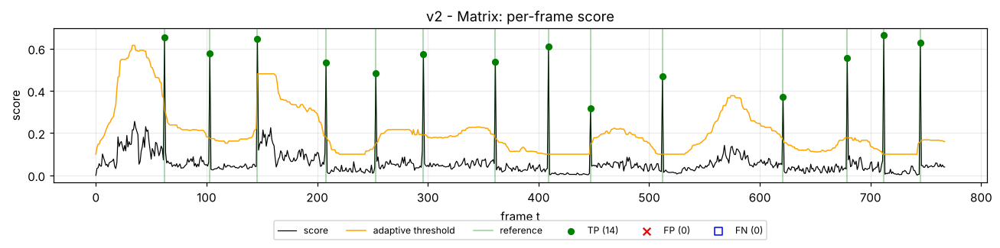

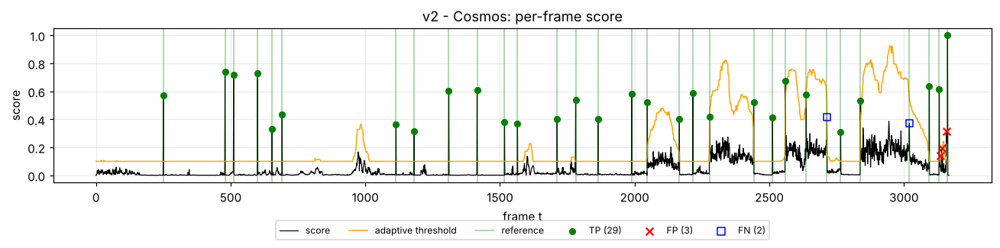

In [10]:
for name in VIDEO:
    VIDEO[name]["score"] = frame_scores(name, layout="hog", before=2, after=2)
show("Matrix", "score", "v2")
show("Cosmos", "score", "v2")

### v1 against v2

In [11]:
print(f"{'':<22}{'video':<8}{'TP':>4}{'FP':>4}{'FN':>4}{'precision':>11}{'recall':>9}{'F1':>8}")
for key, label in [("score_v1", "v1 (first approach)"), ("score", "v2 (final)")]:
    for name in VIDEO:
        r = VIDEO[name]["res"][key]
        print(f"{label:<22}{name:<8}{r['TP']:>4}{r['FP']:>4}{r['FN']:>4}{r['precision']:>11.3f}{r['recall']:>9.3f}{r['F1']:>8.3f}")
m = VIDEO["Matrix"]; ref = REFERENCE["Matrix"]
for key in ["score_v1", "score"]:
    s = m[key]; print(f"Matrix {key}: weakest cut = {s[ref].min():.2f} | strongest non-cut = {np.delete(s, ref).max():.2f}")

                      video     TP  FP  FN  precision   recall      F1
v1 (first approach)   Matrix    14   0   0      1.000    1.000   1.000
v1 (first approach)   Cosmos    30  10   1      0.750    0.968   0.845
v2 (final)            Matrix    14   0   0      1.000    1.000   1.000
v2 (final)            Cosmos    29   3   2      0.906    0.935   0.921
Matrix score_v1: weakest cut = 0.32 | strongest non-cut = 0.26
Matrix score: weakest cut = 0.32 | strongest non-cut = 0.26


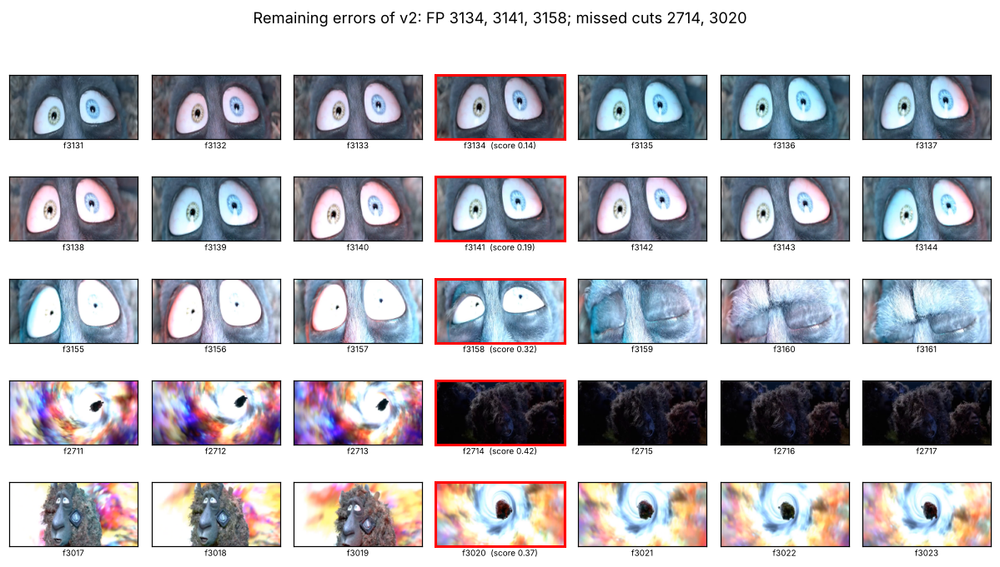

In [12]:
gallery("Cosmos", [3134, 3141, 3158, 2714, 3020], "score", "Remaining errors of v2: FP 3134, 3141, 3158; missed cuts 2714, 3020")

## Sensitivity to the threshold

In [13]:
print(f"{'ratio':>6} | {'v1 Matrix':>10} {'v1 Cosmos':>10} | {'v2 Matrix':>10} {'v2 Cosmos':>10}")
for ratio in [2, 3, 4, 5, 6, 8, 12]:
    row = [match(detect(VIDEO[n][k], **{**PARAMS, "ratio": ratio}), REFERENCE[n])["F1"]
           for k in ["score_v1", "score"] for n in VIDEO]
    print(f"{ratio:>6} | {row[0]:>10.3f} {row[1]:>10.3f} | {row[2]:>10.3f} {row[3]:>10.3f}" + ("   <- frozen" if ratio == PARAMS["ratio"] else ""))

 ratio |  v1 Matrix  v1 Cosmos |  v2 Matrix  v2 Cosmos
     2 |      0.966      0.674 |      0.966      0.899
     3 |      1.000      0.838 |      1.000      0.923
     4 |      1.000      0.845 |      1.000      0.921   <- frozen
     5 |      1.000      0.812 |      1.000      0.900
     6 |      1.000      0.812 |      0.963      0.897
     8 |      0.880      0.848 |      0.963      0.857
    12 |      0.444      0.844 |      0.727      0.808


## Storyboard of the shots found by v2

In [14]:
def shots_from(pred, n):
    starts = [0] + list(pred); ends = [t - 1 for t in pred] + [n - 1]
    return list(zip(starts, ends))

def representative(H, a, b):
    h = H[a:b + 1]; return a + int(np.abs(h - h.mean(0)).sum(1).argmin())

def storyboard(name, first=0, last=None):
    v = VIDEO[name]; T, n = v["thumbs"], len(v["thumbs"]); H = descriptors(name, "hog")[0]
    shots = shots_from(v["pred"]["score"], n); sel = shots[first:last]
    titles = ["before start", "first", "representative", "last", "after end"]
    fig, axes = plt.subplots(len(sel), 5, figsize=(11, 1.15 * len(sel)), squeeze=False)
    for row, (a, b) in zip(axes, sel):
        idx = [max(a - 1, 0), a, representative(H, a, b), b, min(b + 1, n - 1)]
        for j, (ax, f) in enumerate(zip(row, idx)):
            ax.imshow(T[f], aspect=2 / v["ar"]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            ax.set_xlabel(f"{titles[j]}: f{f}", fontsize=6.5, labelpad=1)
    fig.suptitle(f"{name} storyboard: shots {first + 1}-{first + len(sel)} of {len(shots)}", y=1.0)
    plt.tight_layout(); plt.show()

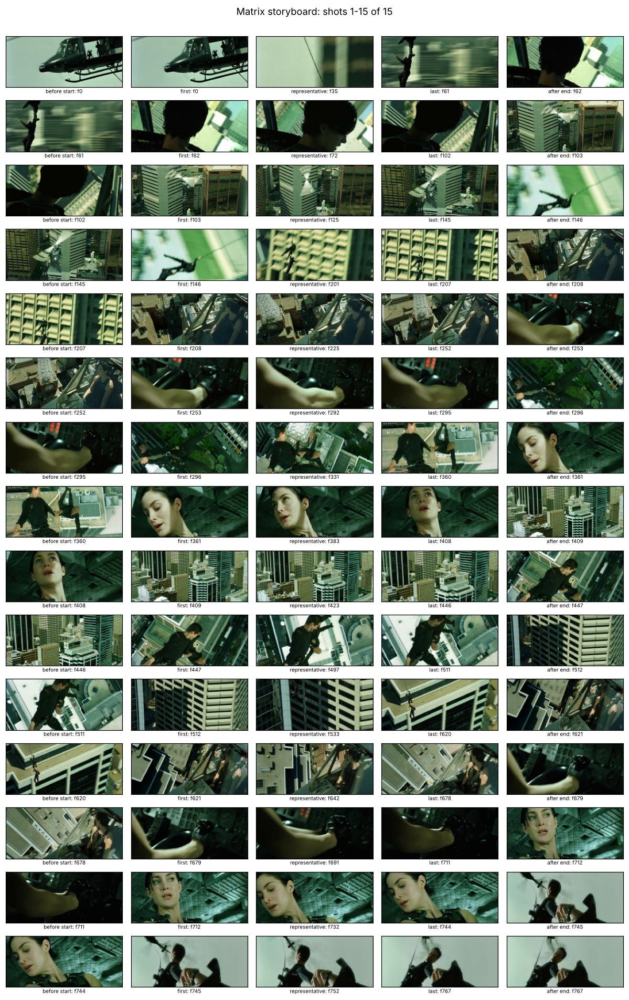

In [15]:
storyboard("Matrix")

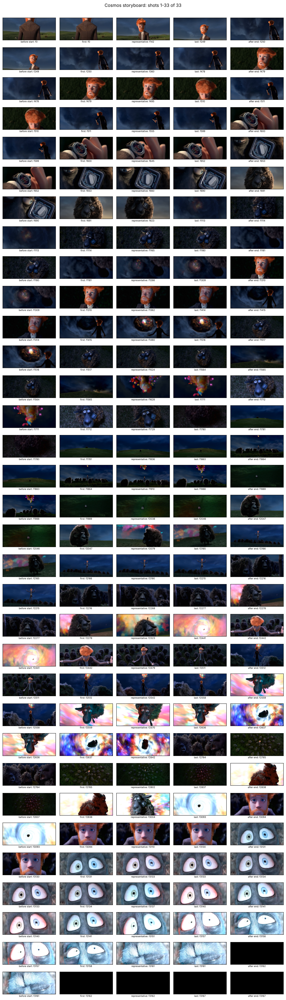

In [16]:
storyboard("Cosmos")